# BÀI THỰC HÀNH SỐ 1 — PHẦN 1 — BÀI 2 (TRANG 30)
## Tiền xử lý và trực quan hóa dữ liệu cảm biến nhà xưởng (`tb_tracking.xlsx`)

**Yêu cầu đề bài (Trang 30):**
- **Câu a:** Đọc dữ liệu `tb_tracking.xlsx` và thêm tiêu đề các cột theo thứ tự: `id`, `device_id`, `co_level`, `humidity`, `temperature`, `time` (đồng thời kiểm tra và loại bỏ các dòng trống / dòng công thức tổng hợp ở cuối sheet).
- **Câu b:** Do điều chỉnh cảm biến nên dữ liệu đo được bắt đầu từ ngày `03/01/2018` (`DD/MM/YYYY`, tức `2018-01-03`) mới chính xác; loại bỏ các dữ liệu trước mốc này.
- **Câu c:** Từ cột `time`, bóc tách thời điểm đo đạc trong ngày tính theo phút, lưu vào cột `minutes`.
- **Câu d:** Vẽ đồ thị phân tán (*scatter plots*) biểu diễn `co_level`, `humidity` và `temperature` theo cột `minutes`, kèm nhận xét về phân bố và bất thường dữ liệu.

In [1]:
# Thiết lập thông tin sinh viên, thư viện và đường dẫn dataset (Local & Google Colab)
STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"
print(f"{STUDENT_NAME} - {MSSV}")

import os
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("openpyxl") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "openpyxl"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.unicode_minus"] = False
sns.set_style("whitegrid")

DATASET_FOLDER_URL = (
    "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing"
)


def get_dataset_path(filename: str) -> str:
    """Tìm file dataset ở ./Dataset, Google Drive (nếu chạy trên Colab), hoặc tải qua gdown."""
    local_path = os.path.join(".", "Dataset", filename)
    if os.path.exists(local_path):
        return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        drive_path = os.path.join("/content/drive/MyDrive/Dataset", filename)
        if os.path.exists(drive_path):
            return drive_path

    if importlib.util.find_spec("gdown") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    subprocess.check_call(
        [sys.executable, "-m", "gdown", "--folder", DATASET_FOLDER_URL, "-O", "Dataset"]
    )
    if os.path.exists(local_path):
        return local_path
    raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu: {filename}")


data_path = get_dataset_path("tb_tracking.xlsx")
print(f"Đường dẫn dữ liệu: {data_path}")

Nguyễn Phạm Bảo Khanh - 6451071033
Đường dẫn dữ liệu: .\Dataset\tb_tracking.xlsx


## Câu a: Đọc dữ liệu, gán tiêu đề cột và làm sạch các dòng tổng hợp cuối tệp

Tệp `tb_tracking.xlsx` **không có dòng tiêu đề** (dòng đầu tiên đã là bản ghi dữ liệu cảm biến `id = 1`), vì vậy cần đọc bằng `pd.read_excel(..., header=None, engine="openpyxl")` và gán trực tiếp tên 6 cột theo đúng thứ tự:
`['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']`.

Khi kiểm tra phần cuối bảng dữ liệu thô, sau 33.336 dòng cảm biến thực (`id` từ `1` đến `33336`), sheet còn chứa:
1. **1 dòng trống ngăn cách** tại chỉ số `33336` (toàn bộ là `NaN`/`NaT`).
2. **3 dòng công thức tổng hợp Excel** (`MIN`, `MAX`, `AVERAGE` trên vùng `A1:F33336`) tại các chỉ số `33337..33339`.

Nếu không loại bỏ các dòng cuối này ngay ở Câu a, dòng `MAX` mang giá trị `time = 2018-01-17 15:46:34` cùng cực trị giả (`co_level = 4030`, `humidity = 11030`, `temperature = 5340310`) sẽ **lọt qua** bộ lọc `time >= 2018-01-03` ở Câu b và làm sai lệch phân tích.

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

columns = ["id", "device_id", "co_level", "humidity", "temperature", "time"]
df_raw = pd.read_excel(data_path, header=None, engine="openpyxl")
df_raw.columns = columns

print(f"Kích thước dữ liệu thô ban đầu: {df_raw.shape}")
print("\n5 dòng đầu dữ liệu thô:")
display(df_raw.head(5))

print("\n5 dòng cuối dữ liệu thô (chú ý dòng trống tại index 33336 và 3 dòng MIN/MAX/AVERAGE ở 33337..33339):")
display(df_raw.tail(5))

# Xác định dòng trống ngăn cách (id bị thiếu) và chỉ giữ lại các dòng cảm biến thực phía trên nó
null_id_indices = df_raw.index[df_raw["id"].isna()].tolist()
if not null_id_indices:
    raise ValueError("Không tìm thấy dòng trống ngăn cách như dự kiến trong tệp tb_tracking.xlsx.")

blank_row_idx = null_id_indices[0]
dropped_tail = df_raw.iloc[blank_row_idx:]
print(f"\nPhát hiện dòng trống tại index {blank_row_idx}; loại bỏ {len(dropped_tail)} dòng cuối (1 dòng trống + 3 dòng MIN/MAX/AVERAGE).")
print("Dòng MAX bị loại bỏ có time =", dropped_tail.iloc[2]["time"],
      "| co_level =", dropped_tail.iloc[2]["co_level"],
      "| humidity =", dropped_tail.iloc[2]["humidity"],
      "| temperature =", dropped_tail.iloc[2]["temperature"])

df = df_raw.iloc[:blank_row_idx].copy()
df["id"] = df["id"].astype("int64")
df["device_id"] = df["device_id"].astype("int64")

assert len(df) == 33336, f"Kỳ vọng 33,336 dòng thực nhưng thu được {len(df)}"
assert df.isna().sum().sum() == 0, "Dữ liệu sau làm sạch vẫn còn giá trị thiếu!"

print(f"\nKích thước dữ liệu sau khi loại bỏ dòng trống và công thức tổng hợp: {df.shape}")
print("Kiểm tra số lượng giá trị null từng cột:")
print(df.isna().sum())
print("\n5 dòng cuối dữ liệu sạch:")
display(df.tail(5))

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước dữ liệu thô ban đầu: (33340, 6)

5 dòng đầu dữ liệu thô:


,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01



5 dòng cuối dữ liệu thô (chú ý dòng trống tại index 33336 và 3 dòng MIN/MAX/AVERAGE ở 33337..33339):


,id,device_id,co_level,humidity,temperature,time
33335,33336.0,0.000000,31.500000,62.000000,2.004240e+06,2018-01-17 15:46:34.000
33336,NaN,NaN,NaN,NaN,NaN,NaT
33337,1.0,-1.000000,0.000000,0.000000,0.000000e+00,2016-12-20 12:52:29.000
33338,33336.0,99005.000000,4030.000000,11030.000000,5.340310e+06,2018-01-17 15:46:34.000
33339,16668.5,97931.172516,181.704089,2127.562065,1.384405e+05,2017-03-15 06:51:12.688



Phát hiện dòng trống tại index 33336; loại bỏ 4 dòng cuối (1 dòng trống + 3 dòng MIN/MAX/AVERAGE).
Dòng MAX bị loại bỏ có time = 2018-01-17 15:46:34 | co_level = 4030.0 | humidity = 11030.0 | temperature = 5340310.0

Kích thước dữ liệu sau khi loại bỏ dòng trống và công thức tổng hợp: (33336, 6)
Kiểm tra số lượng giá trị null từng cột:
id             0
device_id      0
co_level       0
humidity       0
temperature    0
time           0
dtype: int64

5 dòng cuối dữ liệu sạch:


,id,device_id,co_level,humidity,temperature,time
33331,33332,0,32.0,58.0,2049770.0,2018-01-17 15:26:12
33332,33333,0,32.0,58.0,1983470.0,2018-01-17 15:31:18
33333,33334,0,32.0,59.0,2119740.0,2018-01-17 15:36:24
33334,33335,0,32.0,61.0,2096030.0,2018-01-17 15:41:29
33335,33336,0,31.5,62.0,2004240.0,2018-01-17 15:46:34


## Câu b: Chuẩn hóa cột `time` và lọc dữ liệu từ ngày `03/01/2018` trở đi

Trong ngữ cảnh tài liệu tiếng Việt, mốc `"03/01/2018"` tuân theo định dạng `DD/MM/YYYY`, tức **`2018-01-03`** (ngày 03 tháng 01 năm 2018). Toàn bộ dữ liệu cảm biến nằm trong khoảng từ `2016-12-20 12:52:29` đến `2018-01-17 15:46:34` (nên nếu hiểu nhầm thành `2018-03-01` sẽ thu được 0 bản ghi).

Ta chuyển cột `time` sang kiểu `datetime` bằng `pd.to_datetime()` và giữ lại các bản ghi thỏa mãn `df['time'] >= pd.Timestamp('2018-01-03')`.

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

df["time"] = pd.to_datetime(df["time"])
cutoff_date = pd.Timestamp("2018-01-03")

print(f"Tổng số dòng trước khi lọc: {len(df):,}")
print(f"Khoảng thời gian toàn bộ dữ liệu: {df['time'].min()} -> {df['time'].max()}")

df_filtered = df[df["time"] >= cutoff_date].copy()
removed_count = len(df) - len(df_filtered)

print(f"Số dòng bị loại bỏ (trước {cutoff_date.strftime('%d/%m/%Y')}): {removed_count:,}")
print(f"Số dòng hợp lệ còn lại (>= {cutoff_date.strftime('%Y-%m-%d')}): {len(df_filtered):,}")
print(f"Khoảng id còn lại: {df_filtered['id'].min()} .. {df_filtered['id'].max()}")
print(f"Khoảng thời gian sau khi lọc: {df_filtered['time'].min()} -> {df_filtered['time'].max()}")

print("\n5 dòng đầu sau khi lọc:")
display(df_filtered.head(5))
print("\n5 dòng cuối sau khi lọc:")
display(df_filtered.tail(5))

Nguyễn Phạm Bảo Khanh - 6451071033
Tổng số dòng trước khi lọc: 33,336
Khoảng thời gian toàn bộ dữ liệu: 2016-12-20 12:52:29 -> 2018-01-17 15:46:34
Số dòng bị loại bỏ (trước 03/01/2018): 31,419
Số dòng hợp lệ còn lại (>= 2018-01-03): 1,917
Khoảng id còn lại: 31420 .. 33336
Khoảng thời gian sau khi lọc: 2018-01-03 13:11:07 -> 2018-01-17 15:46:34

5 dòng đầu sau khi lọc:


,id,device_id,co_level,humidity,temperature,time
31419,31420,1,2.0,3.0,4.0,2018-01-03 13:11:07
31420,31421,1,2.0,3.0,4.0,2018-01-03 13:15:10
31421,31422,99005,58.0,26.0,0.0,2018-01-03 13:17:30
31422,31423,99005,58.0,26.0,0.0,2018-01-03 13:19:21
31423,31424,99005,58.0,26.0,0.0,2018-01-03 13:24:17



5 dòng cuối sau khi lọc:


,id,device_id,co_level,humidity,temperature,time
33331,33332,0,32.0,58.0,2049770.0,2018-01-17 15:26:12
33332,33333,0,32.0,58.0,1983470.0,2018-01-17 15:31:18
33333,33334,0,32.0,59.0,2119740.0,2018-01-17 15:36:24
33334,33335,0,32.0,61.0,2096030.0,2018-01-17 15:41:29
33335,33336,0,31.5,62.0,2004240.0,2018-01-17 15:46:34


## Câu c: Bóc tách thời điểm đo đạc trong ngày tính theo phút (`minutes`)

Thời điểm trong ngày tính theo phút được quy đổi chính xác từ giờ, phút và giây của cột `time`:
$$\text{minutes} = \text{hour} \times 60 + \text{minute} + \frac{\text{second}}{60}$$
Giá trị thu được nằm trong khoảng `[0, 1440)` (với `0` là `00:00:00` và `1440` tương ứng 24 giờ trong ngày).

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

df_filtered["minutes"] = (
    df_filtered["time"].dt.hour * 60
    + df_filtered["time"].dt.minute
    + df_filtered["time"].dt.second / 60.0
)

print("Thống kê tóm tắt cột 'minutes':")
print(f"  - Min : {df_filtered['minutes'].min():.4f} phút")
print(f"  - Max : {df_filtered['minutes'].max():.4f} phút")
print(f"  - Mean: {df_filtered['minutes'].mean():.4f} phút")
print("\nBảng mô tả chi tiết (describe):")
display(df_filtered["minutes"].describe().to_frame().T)

print("\n5 dòng đầu với cột 'minutes' vừa tạo:")
display(df_filtered[["id", "device_id", "time", "minutes"]].head(5))

Nguyễn Phạm Bảo Khanh - 6451071033
Thống kê tóm tắt cột 'minutes':
  - Min : 1.5000 phút
  - Max : 1439.0000 phút
  - Mean: 709.7938 phút

Bảng mô tả chi tiết (describe):


,count,mean,std,min,25%,50%,75%,max
minutes,1917.0,709.793792,391.935517,1.5,396.183333,713.483333,993.416667,1439.0



5 dòng đầu với cột 'minutes' vừa tạo:


,id,device_id,time,minutes
31419,31420,1,2018-01-03 13:11:07,791.116667
31420,31421,1,2018-01-03 13:15:10,795.166667
31421,31422,99005,2018-01-03 13:17:30,797.500000
31422,31423,99005,2018-01-03 13:19:21,799.350000
31423,31424,99005,2018-01-03 13:24:17,804.283333


## Câu d: Vẽ đồ thị phân tán (*scatter plots*) theo cột `minutes` và phân tích bất thường

Ta vẽ 3 đồ thị phân tán lần lượt cho `co_level`, `humidity` và `temperature` theo `minutes`, đồng thời phân nhóm màu theo `device_id` (`99005`, `0`, `1`) để làm rõ sự khác biệt giữa các thiết bị và các giá trị bất thường trong dữ liệu.

Nguyễn Phạm Bảo Khanh - 6451071033
Thống kê phân bố theo từng device_id (trên 1,917 dòng sau lọc):


co_level                               humidity                  \
             count   min       mean median   max    count   min      mean   
device_id                                                                   
0              192  26.0  29.559896   30.0  62.0      192  43.0  60.50000   
1                2   2.0   2.000000    2.0   2.0        2   3.0   3.00000   
99005         1723  22.0  28.068485   28.0  77.0     1723   6.0  70.01567   

                       temperature                                      \
          median   max       count        min          mean     median   
device_id                                                                
0           59.0  80.0         192  1749660.0  2.286410e+06  2163445.0   
1            3.0   3.0           2        4.0  4.000000e+00        4.0   
99005       71.0  86.0        1723        0.0  2.369788e+06  2349490.0   

                      
                 max  
device_id             
0          5340310.0  
1                4.0  
99005      4394300.0

Số dòng test device_id == 1 (co=2, hum=3, temp=4): 2
Số dòng có temperature == 0: 22
Số dòng có temperature == 1: 3


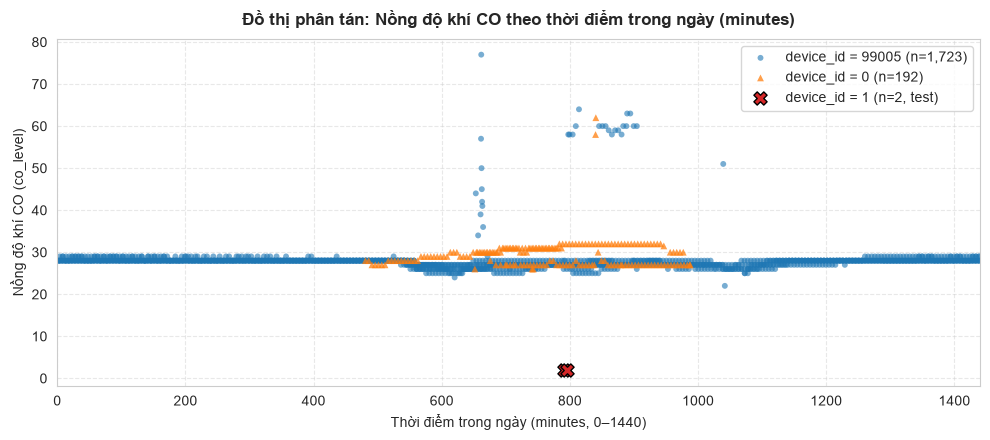

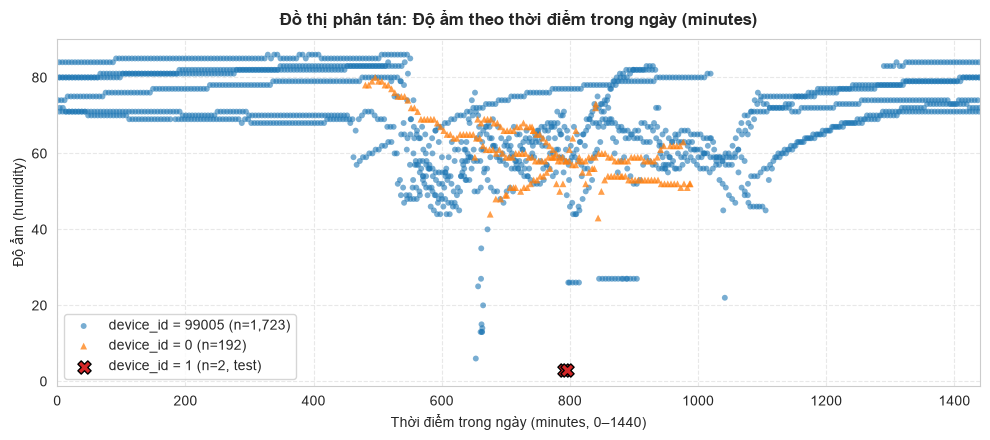

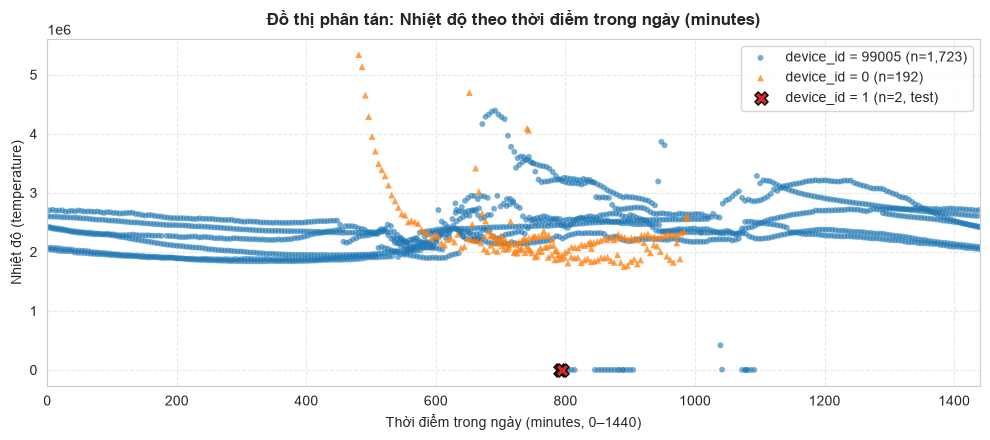

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

print("Thống kê phân bố theo từng device_id (trên 1,917 dòng sau lọc):")
device_summary = (
    df_filtered.groupby("device_id")[["co_level", "humidity", "temperature"]]
    .agg(["count", "min", "mean", "median", "max"])
)
display(device_summary)

zero_temp_count = (df_filtered["temperature"] == 0).sum()
one_temp_count = (df_filtered["temperature"] == 1).sum()
test_dev1_count = (df_filtered["device_id"] == 1).sum()
print(f"Số dòng test device_id == 1 (co=2, hum=3, temp=4): {test_dev1_count}")
print(f"Số dòng có temperature == 0: {zero_temp_count}")
print(f"Số dòng có temperature == 1: {one_temp_count}")

# Cấu hình màu và nhãn riêng cho từng device_id để nhận diện bất thường rõ ràng trên biểu đồ
device_styles = {
    99005: {"color": "#1f77b4", "label": "device_id = 99005 (n=1,723)", "s": 18, "alpha": 0.60, "marker": "o"},
    0: {"color": "#ff7f0e", "label": "device_id = 0 (n=192)", "s": 24, "alpha": 0.75, "marker": "^"},
    1: {"color": "#d62728", "label": "device_id = 1 (n=2, test)", "s": 90, "alpha": 1.00, "marker": "X"},
}

metrics = [
    ("co_level", "Nồng độ khí CO (co_level)", "Đồ thị phân tán: Nồng độ khí CO theo thời điểm trong ngày (minutes)"),
    ("humidity", "Độ ẩm (humidity)", "Đồ thị phân tán: Độ ẩm theo thời điểm trong ngày (minutes)"),
    ("temperature", "Nhiệt độ (temperature)", "Đồ thị phân tán: Nhiệt độ theo thời điểm trong ngày (minutes)"),
]

for col, ylabel, title in metrics:
    plt.figure(figsize=(10, 4.5))
    for dev_id, style in device_styles.items():
        subset = df_filtered[df_filtered["device_id"] == dev_id]
        plt.scatter(
            subset["minutes"],
            subset[col],
            c=style["color"],
            label=style["label"],
            s=style["s"],
            alpha=style["alpha"],
            marker=style["marker"],
            edgecolors="none" if dev_id != 1 else "black",
        )
    plt.title(title, fontsize=12, fontweight="bold", pad=10)
    plt.xlabel("Thời điểm trong ngày (minutes, 0–1440)", fontsize=10)
    plt.ylabel(ylabel, fontsize=10)
    plt.xlim(0, 1440)
    plt.grid(True, linestyle="--", alpha=0.45)
    plt.legend(loc="best", frameon=True)
    plt.tight_layout()
    plt.show()

### Nhận xét về phân bố và các điểm bất thường dữ liệu (Câu d)

1. **Phân bố theo thời điểm trong ngày (`minutes`):**
   - Các phép đo trải đều gần như trọn vẹn 24 giờ trong ngày, từ **`1.50` phút** (`00:01:30`) đến **`1439.00` phút** (`23:59:00`), giá trị trung bình **`709.79` phút** (~11:50 trưa), phản ánh hệ thống cảm biến giám sát nhà xưởng liên tục cả ngày lẫn đêm.
2. **Phân bố `co_level` (Nồng độ khí CO):**
   - Phần lớn các điểm tập trung ổn định trong dải **`25–32`** (Q1 = `27`, trung vị = `28`, Q3 = `28`).
   - Xuất hiện một số cụm giá trị tăng cao cục bộ từ **`41` đến `77`** vào khung buổi sáng–đầu giờ chiều (khoảng `minutes` `650–905`, tức ~10:50–15:05, tương ứng các ngày `03/01` và `12/01`).
   - Có 2 điểm ngoại lai thấp `co_level = 2` của `device_id = 1` ở khoảng `minutes ~ 791–795`.
3. **Phân bố `humidity` (Độ ẩm):**
   - Đa số điểm đo dao động từ **`50` đến `86`** (trung vị **`70`**), trong đó `device_id = 0` nằm thấp hơn nhẹ (`43–80`, trung bình `60.5`) so với `device_id = 99005` (`6–86`, trung bình `70.0`).
   - Xuất hiện cụm điểm giảm ẩm bất thường xuống **`6–35`** (vào khoảng `minutes` `653–905`, trùng thời điểm CO tăng cao) và 2 điểm giả `humidity = 3` ở `device_id = 1`.
4. **Phân bố `temperature` và bất thường nghiêm trọng về thang đo / thiết bị:**
   - **Thang đo cực lớn (`~10^6`)**: Hầu hết các giá trị hợp lệ nằm quanh **`1.75 × 10^6` đến `5.34 × 10^6`** (trung vị **`2.33 × 10^6`**), không phải đơn vị độ C thông thường (có thể là giá trị thô chưa quy đổi hệ số `10^5` hoặc lỗi mã hóa cảm biến).
   - **Các điểm rơi về 0 hoặc gần 0 (`device_id = 99005`)**: Có **`22` dòng `temperature = 0`** và **`3` dòng `temperature = 1`** (cùng `1` dòng `5,452` và `1` dòng `415,404`) tập trung ngay ngày `03/01/2018` khi cảm biến vừa bắt đầu điều chỉnh lại.
   - **Dữ liệu kiểm thử (`device_id = 1`)**: Đúng `2` bản ghi đầu tiên sau mốc `03/01/2018` (`id = 31420, 31421` lúc `13:11`–`13:15`) mang chuỗi giá trị giả tuần tự `(device_id=1, co_level=2, humidity=3, temperature=4)`.
   - **Thiết bị `device_id = 0` (`192` dòng)**: Vừa có `device_id = 0` (thường đại diện thiết bị mặc định/chưa định danh), vừa ghi nhận mức `temperature` cao vọt tới **`5,340,310`**.

**Khuyến nghị tiền xử lý tiếp theo:** Trước khi huấn luyện mô hình hoặc báo cáo vận hành, cần loại bỏ 2 dòng test `device_id = 1`, xử lý các bản ghi `temperature ∈ {0, 1}` bị mất tín hiệu, và kiểm tra hệ số hiệu chuẩn thang đo của `temperature` theo từng `device_id`.